## Implement Spatial Domain Filtering
---

#### Averaging Filter

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [13]:
img = cv2.imread('Itachi.jpg', 0)

In [14]:
m, n = img.shape

Develop Average Filter (3, 3) mask

In [15]:
mask = np.ones([3, 3], dtype=int)
mask = mask / 9

Convolve the 3X3 mask over the image

In [16]:
img_new = np.zeros([m, n])

In [17]:
for i in range(1, m-1):
    for j in range(1, n-1):
        temp = img[i-1, j-1] * mask[0, 0] + img[i-1, j] * mask[0, 1] + img[i-1, j+1] * mask[0, 2] + img[i, j-1] * mask[1, 0] + img[i, j] * mask[1, 1] + img[i, j+1] * mask[1, 2] + img[i+1, j-1] * mask[2, 0] + img[i+1, j] * mask[2, 1] + img[i+1, j+1] * mask[2, 2]
        img_new[i, j] = temp

In [18]:
img_new = img_new.astype(np.uint8)

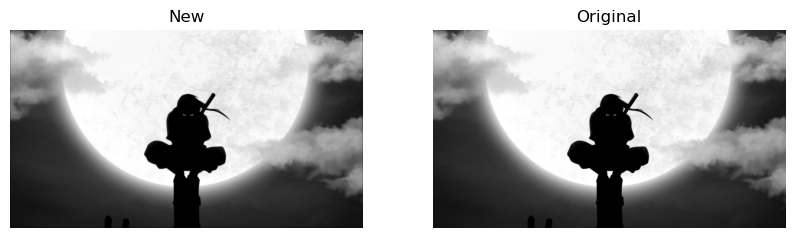

In [19]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title('New')
plt.imshow(cv2.cvtColor(img_new, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Original')
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()

---

Median Filter

In [20]:
img_noisy1 = cv2.imread('noisy.png', 0)

In [21]:
m, n = img_noisy1.shape

Traverse the image. For every 3 x 3 area, find the median of the pixels and replace the center pixel by the median

In [27]:
img_new1 = img_noisy1.copy()

for i in range(1, m - 1):
    for j in range(1, n - 1):

        temp = [
            img_noisy1[i-1, j-1], img_noisy1[i-1, j], img_noisy1[i-1, j+1],
            img_noisy1[i,   j-1], img_noisy1[i,   j], img_noisy1[i,   j+1],
            img_noisy1[i+1, j-1], img_noisy1[i+1, j], img_noisy1[i+1, j+1]
        ]

        temp = sorted(temp)
        img_new1[i, j] = temp[4]

img_new1 = img_new1.astype(np.uint8)

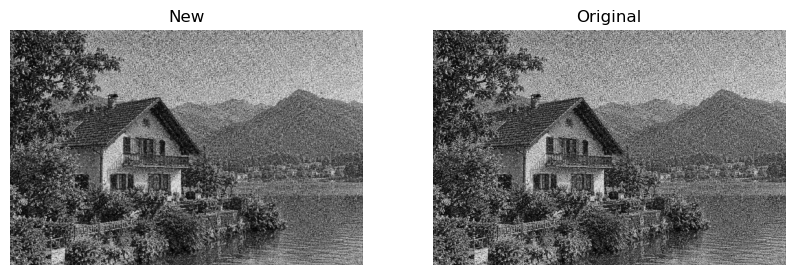

In [28]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title('New')
plt.imshow(cv2.cvtColor(img_new1, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Original')
plt.imshow(cv2.cvtColor(img_noisy1, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()